# Importing Libraries

In [2]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

# Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Prophet
from prophet import Prophet

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings('ignore')

# Load dataset

In [3]:
# Load dataset
health_df = pd.read_csv('health_indicators.csv')

print(health_df.shape)
health_df.head()

(5275, 48)


,country_code,country_name,region,income_level,year,population,population_growth,urban_pct,life_expectancy,life_expectancy_male,...,stunting_pct,wasting_pct,overweight_children_pct,undernourishment_pct,fertility_rate,adolescent_fertility,prenatal_care_pct,gdp_per_capita,gdp_per_capita_ppp,poverty_rate
0,ABW,Aruba,Latin America & Caribbean,High income,2000,90588.0,1.030817,65.354550,72.939,70.149,...,NaN,NaN,NaN,NaN,1.845,43.729,NaN,20681.023027,30245.706974,NaN
1,ABW,Aruba,Latin America & Caribbean,High income,2001,91439.0,0.935033,65.335114,73.044,70.251,...,NaN,NaN,NaN,NaN,1.813,40.463,NaN,20740.132583,31920.239073,NaN
2,ABW,Aruba,Latin America & Caribbean,High income,2002,92074.0,0.692052,65.282069,73.135,70.364,...,NaN,NaN,NaN,NaN,1.800,38.185,NaN,21307.248251,31888.508737,NaN
3,ABW,Aruba,Latin America & Caribbean,High income,2003,93128.0,1.138229,65.198292,73.236,70.488,...,NaN,NaN,NaN,NaN,1.808,37.807,NaN,21949.485996,32507.084315,NaN
4,ABW,Aruba,Latin America & Caribbean,High income,2004,95138.0,2.135358,65.088653,73.223,70.487,...,NaN,NaN,NaN,NaN,1.819,38.761,NaN,23700.631990,35059.273098,NaN


# Extract Kenya Data

In [13]:
kenya_df = health_df.loc[
    health_df['country_name'].eq('Kenya'),
    [
        'year',
        'life_expectancy',
        'maternal_mortality',
        'under5_mortality',
        'health_expenditure_pct_gdp',
        'gdp_per_capita',
        'physicians_per_1000',
        'hospital_beds_per_1000',
        'population',
    ]
].copy()

kenya_df.head()


,year,life_expectancy,maternal_mortality,under5_mortality,health_expenditure_pct_gdp,gdp_per_capita,physicians_per_1000,hospital_beds_per_1000,population
2400,2000,56.084,206.0,95.2,3.624514,414.626365,NaN,NaN,30642890.0
2401,2001,56.501,188.0,90.5,3.740023,410.700452,NaN,NaN,31619170.0
2402,2002,56.759,182.0,85.6,3.821595,402.936386,0.138,NaN,32629808.0
2403,2003,57.369,177.0,80.8,4.033657,442.898457,NaN,NaN,33652223.0
2404,2004,57.947,177.0,76.1,4.211595,463.662781,NaN,1.4,34713455.0


# Exploratory Data Analysis

In [14]:
kenya_df.head()

kenya_df.info()

kenya_df.describe()

kenya_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 2400 to 2424
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   year                        25 non-null     int64  
 1   life_expectancy             25 non-null     float64
 2   maternal_mortality          24 non-null     float64
 3   under5_mortality            25 non-null     float64
 4   health_expenditure_pct_gdp  24 non-null     float64
 5   gdp_per_capita              25 non-null     float64
 6   physicians_per_1000         13 non-null     float64
 7   hospital_beds_per_1000      3 non-null      float64
 8   population                  25 non-null     float64
dtypes: float64(8), int64(1)
memory usage: 1.9 KB


year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
population                     0
dtype: int64

MISSING VALUES

In [15]:
missing_values = kenya_df.isnull().sum()
print(missing_values)

year                           0
life_expectancy                0
maternal_mortality             1
under5_mortality               0
health_expenditure_pct_gdp     1
gdp_per_capita                 0
physicians_per_1000           12
hospital_beds_per_1000        22
population                     0
dtype: int64


In [17]:
# Handle missing values for numeric columns by converting them to numeric types and imputing with median values
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns
kenya_df[numeric_cols] = kenya_df[numeric_cols].apply(pd.to_numeric, errors='coerce')

In [19]:
numeric_cols = kenya_df.select_dtypes(include=['float64','int64']).columns

imputer = SimpleImputer(strategy='median')

nonempty_numeric_cols = kenya_df[numeric_cols].columns[
    kenya_df[numeric_cols].notna().any()
]

kenya_df[nonempty_numeric_cols] = imputer.fit_transform(
    kenya_df[nonempty_numeric_cols]
)

VISUALISATIONS

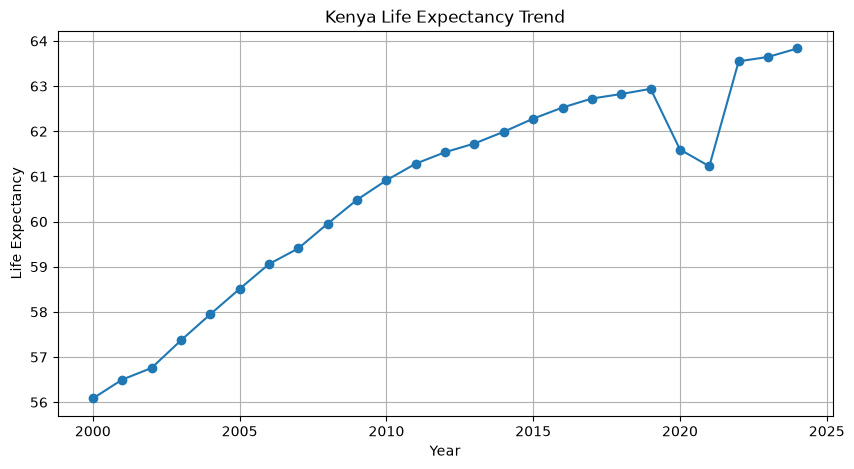

In [20]:
plt.figure(figsize=(10,5))

plt.plot(
    kenya_df['year'],
    kenya_df['life_expectancy'],
    marker='o'
)

plt.title('Kenya Life Expectancy Trend')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.grid(True)

plt.show()


# Modelling

## Prophet model

Preparing dataset for prophet model 

In [22]:
prophet_df = kenya_df.copy()

prophet_df = prophet_df[['year', 'life_expectancy']].rename(
    columns={'year': 'ds', 'life_expectancy': 'y'}
)

prophet_df['ds'] = pd.to_datetime(
    prophet_df['ds'].astype(int).astype(str),
    format='%Y'
)

prophet_df.head()


,ds,y
2400,2000-01-01,56.084
2401,2001-01-01,56.501
2402,2002-01-01,56.759
2403,2003-01-01,57.369
2404,2004-01-01,57.947


Training and testing model

In [23]:
train = prophet_df[:-5]
test = prophet_df[-5:]

model = Prophet()

model.fit(train)

future = model.make_future_dataframe(
    periods=5,
    freq='YE'
)

forecast = model.predict(future)

19:59:20 - cmdstanpy - INFO - Chain [1] start processing
19:59:41 - cmdstanpy - INFO - Chain [1] done processing


Visualisation

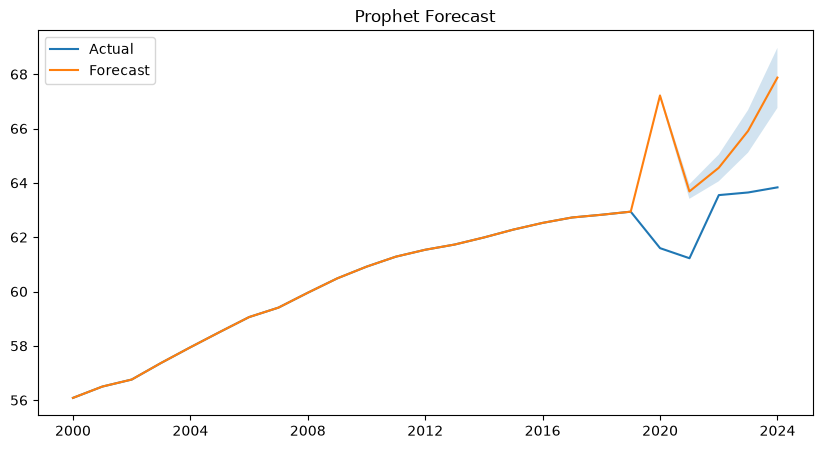

In [24]:
plt.figure(figsize=(10,5))

plt.plot(
    prophet_df['ds'],
    prophet_df['y'],
    label='Actual'
)

plt.plot(
    forecast['ds'],
    forecast['yhat'],
    label='Forecast'
)

plt.fill_between(
    forecast['ds'],
    forecast['yhat_lower'],
    forecast['yhat_upper'],
    alpha=0.2
)

plt.legend()
plt.title('Prophet Forecast')

plt.show()

Model Evaluation

In [25]:
prophet_pred = forecast['yhat'].tail(len(test))

prophet_mae = mean_absolute_error(
    test['y'],
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        test['y'],
        prophet_pred
    )
)

print("Prophet MAE:", prophet_mae)
print("Prophet RMSE:", prophet_rmse)

Prophet MAE: 3.0781062218252986
Prophet RMSE: 3.466830246744499


## LSTM 

Preparing data for LSTM

In [26]:
series = prophet_df['y'].values.reshape(-1,1)

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(series)

Creating sequences

In [27]:
def create_sequences(data, window=3):
    
    X = []
    y = []

    for i in range(len(data)-window):

        X.append(data[i:i+window])
        y.append(data[i+window])

    return np.array(X), np.array(y)

X, y = create_sequences(
    scaled_data,
    window=3
)

Training and testing split

In [28]:
split = int(len(X)*0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

Reshaping data

In [29]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

Building LSTM Model

In [30]:
model = Sequential()

model.add(
    LSTM(
        64,
        return_sequences=True,
        input_shape=(3,1)
    )
)

model.add(
    Dropout(0.2)
)

model.add(
    LSTM(32)
)

model.add(
    Dense(1)
)

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 3, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

Train LSTM

In [31]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_data=(X_test,y_test),
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - loss: 0.3725 - val_loss: 0.6027
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.2955 - val_loss: 0.4720
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.2176 - val_loss: 0.3366
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.1382 - val_loss: 0.1993
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0666 - val_loss: 0.0816
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0111 - val_loss: 0.0296
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0069 - val_loss: 0.0437
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0203 - val_loss: 0.0367
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0081 - val_loss: 0.0293
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0059 - val_loss: 0.0346
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0051 - val_loss: 0.0372
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0053 - val_loss

Predict Test Data

In [32]:
predictions = model.predict(X_test)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(
    y_test
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 655ms/step


Evaluate LSTM

In [33]:
mae = mean_absolute_error(
    actual,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

r2 = r2_score(
    actual,
    predictions
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1.2849906555175792
RMSE: 1.3933880901277858
R²: -0.5478713850294001


Actual vs Predicted

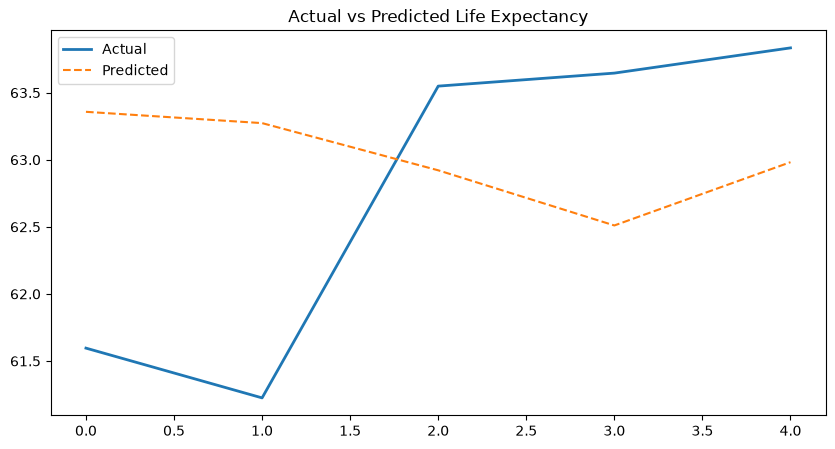

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    actual,
    label='Actual',
    linewidth=2
)

plt.plot(
    predictions,
    label='Predicted',
    linestyle='--'
    
)

plt.title(
    'Actual vs Predicted Life Expectancy'
)

plt.legend()

plt.show()

# Model Comparison

In [35]:
comparison = pd.DataFrame({

    'Model': ['Prophet','LSTM'],

    'MAE': [
        prophet_mae,
        mae
    ],

    'RMSE': [
        prophet_rmse,
        rmse
    ]
})

print(comparison)

     Model       MAE      RMSE
0  Prophet  3.078106  3.466830
1     LSTM  1.284991  1.393388


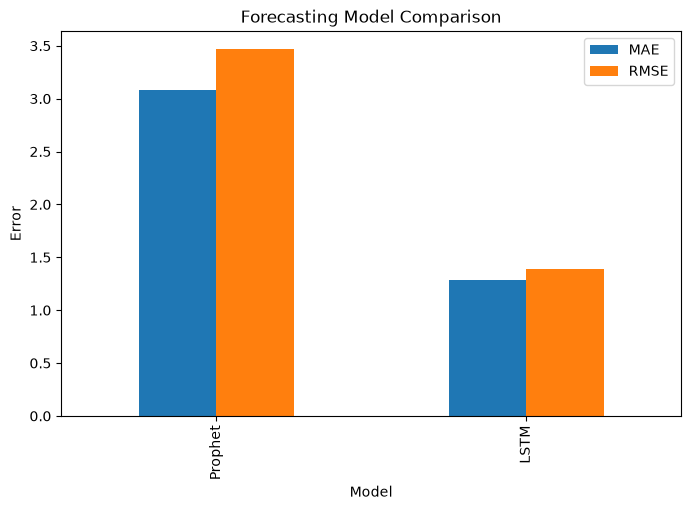

In [36]:
# Visualize the comparison of MAE and RMSE for Prophet and LSTM models
comparison.set_index('Model')[['MAE','RMSE']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title(
    'Forecasting Model Comparison'
)

plt.ylabel('Error')

plt.show()

# Future forecasting using LSTM (Best Model)

In [37]:
last_sequence = scaled_data[-3:]

future_predictions = []

for i in range(6):

    pred = model.predict(
        last_sequence.reshape(1,3,1),
        verbose=0
    )

    future_predictions.append(pred[0,0])

    last_sequence = np.append(
        last_sequence[1:],
        pred
    )

Conversion back to the original scale

In [38]:
future_predictions = scaler.inverse_transform(
    np.array(
        future_predictions
    ).reshape(-1,1)
)

Create Forecast Table

In [39]:
last_year = kenya_df['year'].max()

future_years = [
    last_year + i
    for i in range(1,7)
]

future_forecast = pd.DataFrame({

    'Year': future_years,

    'Predicted_Life_Expectancy':
    future_predictions.flatten()
})

future_forecast

,Year,Predicted_Life_Expectancy
0,2025.0,64.022377
1,2026.0,64.131744
2,2027.0,64.269623
3,2028.0,64.390144
4,2029.0,64.482689
5,2030.0,64.579117


Visualise Future Forecast

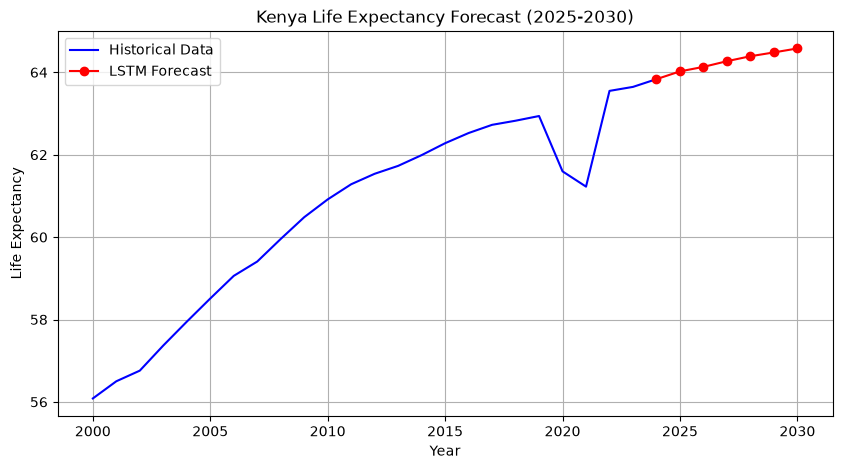

In [41]:
# Visualize future**redictions with connected lines

plt.figure(figsize=(10,5))

# Historical data
plt.plot(
    kenya_df['year'],
    kenya_df['life_expectancy'],
    label='Historical Data',
    color='blue'
)

# Connect forecast to last actual point
forecast_years = [kenya_df['year'].iloc[-1]] + future_years
forecast_values = [kenya_df['life_expectancy'].iloc[-1]] + list(future_predictions.flatten())

plt.plot(
    forecast_years,
    forecast_values,
    marker='o',
    color='red',
    label='LSTM Forecast'
)

plt.title('Kenya Life Expectancy Forecast (2025-2030)')
plt.xlabel('Year')
plt.ylabel('Life Expectancy')
plt.legend()
plt.grid(True)

plt.show()